In [93]:
"""
This notebook is to:
(1) apply bias-correction to the extracted moorings (30 layers profiles)
(2) save the data
(3) plot the comparison for OCNMS bottom moorings before and after bias-correction
"""

'\nThis notebook is to train OCNMS data using saved bias_corrected_model\n\nplot in 3 subplot\n'

In [17]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import gsw
import pickle
import xarray as xr
from lo_tools import Lfun, zfun
from matplotlib.lines import Line2D
from sklearn.metrics import mean_squared_error
from pathlib import Path

import tensorflow as tf
from tensorflow.keras.models import load_model
# scale parameters
from sklearn.preprocessing import StandardScaler
import joblib

Ldir = Lfun.Lstart()

In [2]:
plt.style.use('default')

plt.rcParams.update({
    'axes.labelsize': 18,          # Labels font size
    'xtick.labelsize': 15,         # X-axis ticks font size
    'ytick.labelsize': 15,         # Y-axis ticks font size
    'axes.labelweight': 'bold',    # Bold axis labels
    'xtick.direction': 'in',       # X-axis tick direction
    'ytick.direction': 'in',       # Y-axis tick direction
    'font.size': 15,               # Default font size for other text
})

In [5]:
add_hake_hpic = False
add_hake_hpic_trawl = True
cid_split = True
cast_balanced = True
z_fraction = True
benthic_aware = False
hypoxia_aware = False
hypoxia_shelf_aware = False
hypoxia_two_tier_shelf_aware = True
hypoxia_shelf_smooth_aware = False
remove_NO3 = True
add_3_feature = False
add_DO_gradient = False
add_SA_gradient = False
add_CT_gradient =  False


# add_SA_gradient = False
if add_hake_hpic:
    runame = 'with_hake_hpic'
    if cid_split:
        name = 'cid_split'
        if cast_balanced:
            name += '_cast_balanced'
        if remove_NO3:
            name = 'cid_split_no_NO3'
        if add_CT_gradient and add_SA_gradient and add_DO_gradient:
            name += '_dDO_dz_dCT_dz_dSA_dz'
        elif add_DO_gradient:
            name += '_dDO_dz'
        elif add_CT_gradient:
            name += '_dCT_dz'
        elif add_SA_gradient:
            name += '_dSA_dz'
    else:
        name = ''
elif add_hake_hpic_trawl:
    runame = 'with_hake_hpic_trawl'
    if cid_split:
        name = 'cid_split'
        if cast_balanced:
            name += '_cast_balanced'
            if cast_balanced and z_fraction:
                name += '_z_fraction'
            if cast_balanced and benthic_aware:
                name += '_benthic_aware'
            if cast_balanced and hypoxia_aware:
                name += '_hypoxia_aware'
            if cast_balanced and hypoxia_shelf_aware:
                name += '_hypoxia_shelf_aware'
            if cast_balanced and hypoxia_shelf_smooth_aware:
                name += '_hypoxia_shelf_smooth_aware'
            if cast_balanced and hypoxia_two_tier_shelf_aware:
                name += '_hypoxia_two_tier_shelf_aware'
            if remove_NO3:
                name += '_no_NO3'
            if add_3_feature:
                name += 'add_3_feature'
    else:
        name = ''
else:
    runame = ''
    name = ''

in_dir = Ldir['LOo'] / 'LO_bias_corr' / 'keras' / runame / name
print(in_dir)
# model = load_model(f'{in_dir}/DO_bias_corr.keras')
model = load_model(f'{in_dir}/DO_bias_corr_best_model.keras')


/b1/yifan/LO_output/LO_bias_corr/keras/with_hake_hpic_trawl/cid_split_cast_balanced_z_fraction_hypoxia_two_tier_shelf_aware_no_NO3


In [6]:
# read moor_data
gtx = 'cas2k_v4_lo2b'
folder = 'OCNMS'
moor_dir = Ldir['LOo']/'extract'/gtx/'moor'/folder/'hourly'
Lfun.make_dir(moor_dir)

obs_dir = Ldir['LOo']/'obs'/folder/'moor'
Lfun.make_dir(obs_dir)
# where to put output figures
fig_dir = Ldir['LOo'] / 'LO_bias_corr' / 'plots' / 'mooring'
Lfun.make_dir(fig_dir)

In [7]:
if folder == 'OCNMS':
    sn_list = [
        # 'CA015',
        # 'CA042',
        # # 'CE015',  # depth doesn't match with real mooring, too deep, so skip
        # 'MB042',
        # 'CA065',
        # 'TH042',
        # 'KL027',
        'CE042',
        'CE065',

    ]

In [19]:
daily = False

for sn in sn_list:
    print(sn)
    moor_fn = str(obs_dir/f'{sn}_2000_2023_hourly.nc')
    MOOR = xr.open_dataset(moor_fn)
    if sn in ['CA015','CA042','TH042']:
        fn = str(moor_dir/f'{sn}_2006.01.01_2022.12.30.nc')
    elif sn =='CE042':
        fn = str(moor_dir/f'{sn}_2006.01.01_2022.12.30.nc')
    elif sn == 'CE015' or sn == 'CA065':
        fn = str(moor_dir/f'{sn}_2006.01.01_2012.12.31.nc')
    elif sn =='MB042':
        fn = str(moor_dir/f'{sn}_2012.01.01_2022.12.30.nc')
    elif sn =='KL027':
        fn = str(moor_dir/f'{sn}_2009.01.01_2022.12.30.nc')
    else:
        fn = str(moor_dir/f'{sn}_2006.01.01_2011.12.31.nc')
    dss = xr.open_dataset(fn)
    if daily:
        OBS = (
        MOOR.assign_coords(time=MOOR["time"])
       .swap_dims({"index": "time"})
       .resample(time="1D")
       .mean()
        )
        ds = dss.resample(ocean_time="1D").mean()
        f_str = 'daily'
    else:
        OBS = MOOR.copy()
        ds = dss.copy()
        f_str = 'hourly'

    ot = ds.ocean_time.values
    VN_list = []
    for vn in ds.data_vars:
        # print('%s %s' % (vn, ds[vn].shape))
        VN_list.append(vn)
    vn3_list = []
    if 'salt' in VN_list:
        vn3_list += ['salt', 'temp','oxygen', 'NO3']

    vn3_list = [item for item in vn3_list if item in ds.data_vars]
    df = xr.Dataset(coords={
    'ocean_time': ot,
    's_rho': ds.s_rho
    })
    testing = False
    for vn in vn3_list:
        if testing:
            df[vn] = ds[vn]
        else:
            df[vn] = xr.DataArray(
            zfun.lowpass(
                ds[vn].values,
                f='godin',
            ),
            dims=ds[vn].dims,
            coords=ds[vn].coords
        )

    if add_3_feature:
        profile_list = profile_list = [
                'DO_model_surface_minus_bottom',
                'DO_model_profile_mean',
                'DO_model_profile_min'
            ]
        for vn in profile_list:
            if vn == 'DO_model_surface_minus_bottom':
                df[vn] = (ds['oxygen'].isel(s_rho=-1) -
                          ds['oxygen'].isel(s_rho=0)).values

            if vn == 'DO_model_profile_mean':
                df[vn] = ds['oxygen'].mean(dim='s_rho').values

            if vn == 'DO_model_profile_min':
                df[vn] = ds['oxygen'].min(dim='s_rho').values



    # -------------------------------------------------------
    # 1. Prepare full 30-layer mooring data
    # -------------------------------------------------------
    time = pd.DatetimeIndex(ot)
    nt = len(time)
    nz = ds.sizes['s_rho']

    # Ensure all arrays have shape (time, s_rho)
    def get_profile(vn):
        return ds[vn].transpose('ocean_time', 's_rho').values

    def lowpass_profile(vn):
        return zfun.lowpass(get_profile(vn), f='godin')

    # Apply Godin filter along time for every layer
    SP = lowpass_profile('salt')
    PT = lowpass_profile('temp')
    DO = lowpass_profile('oxygen')
    NO3 = lowpass_profile('NO3')
    z = lowpass_profile('z_rho')

    # Mooring location and bathymetry
    lat0 = float(np.asarray(ds['lat_rho'].values).flat[0])
    lon0 = float(np.asarray(ds['lon_rho'].values).flat[0])
    H = float(np.asarray(ds['h'].values).flat[0])

    lat = np.full((nt, nz), lat0)
    lon = np.full((nt, nz), lon0)
    h = np.full((nt, nz), -abs(H))

    z_fraction_all = np.clip(np.abs(z) / np.abs(h), 0, 1)

    # 1. convert the moor -potential temp to CT
    # 2. convert the salt to SA
    # 3. append 'DO_obs'
    # -------------------------------------------------------
    # 2. Calculate SA and CT at all layers
    # -------------------------------------------------------
    p = gsw.p_from_z(z, lat)
    SA = gsw.SA_from_SP(SP, p, lon, lat)
    CT = gsw.CT_from_pt(SA, PT)

    # -------------------------------------------------------
    # 3. Seasonal predictors
    # -------------------------------------------------------
    doy = time.dayofyear.to_numpy()

    sin_t = np.broadcast_to(
        np.sin(2 * np.pi * doy / 365)[:, None],
        (nt, nz)
    )

    cos_t = np.broadcast_to(
        np.cos(2 * np.pi * doy / 365)[:, None],
        (nt, nz)
    )

    # -------------------------------------------------------
    # 4. Construct flattened feature DataFrame
    # -------------------------------------------------------
    # MultiIndex: one row per time and vertical layer
    idx = pd.MultiIndex.from_product(
        [time, np.arange(nz)],
        names=['time', 's_rho']
    )

    feature_arrays = {
        'lon': lon,
        'lat': lat,
        'z': z,
        'h': h,
        'z_fraction': z_fraction_all,
        'cos_t': cos_t,
        'sin_t': sin_t,
        'CT': CT,
        'SA': SA,
        'DO (uM)': DO,
        'NO3 (uM)': NO3,
    }

    df = pd.DataFrame(
        {name: arr.reshape(-1) for name, arr in feature_arrays.items()},
        index=idx
    )

    # -------------------------------------------------------
    # 5. Optional profile features
    # -------------------------------------------------------
    if add_3_feature:
        df['DO_model_surface_minus_bottom'] = np.broadcast_to(
            (DO[:, -1] - DO[:, 0])[:, None],
            (nt, nz)
        ).reshape(-1)

        df['DO_model_profile_mean'] = np.broadcast_to(
            np.nanmean(DO, axis=1)[:, None],
            (nt, nz)
        ).reshape(-1)

        df['DO_model_profile_min'] = np.broadcast_to(
            np.nanmin(DO, axis=1)[:, None],
            (nt, nz)
        ).reshape(-1)

    # Vertical gradients
    if add_CT_gradient:
        df['dCT_dz'] = np.gradient(CT, axis=1) .reshape(-1) / np.gradient(z, axis=1).reshape(-1)

    if add_SA_gradient:
        df['dSA_dz'] = np.gradient(SA, axis=1).reshape(-1) / np.gradient(z, axis=1).reshape(-1)

    if add_DO_gradient:
        df['dDO_dz'] = np.gradient(DO, axis=1).reshape(-1) / np.gradient(z, axis=1).reshape(-1)

    # -------------------------------------------------------
    # 6. Select predictors (same as training)
    # -------------------------------------------------------
    vn = [
        'lon', 'lat', 'z',
        'cos_t', 'sin_t',
        'CT', 'SA',
        'DO (uM)', 'NO3 (uM)'
    ]

    if remove_NO3:
        vn.remove('NO3 (uM)')
    z_fraction = True
    if cast_balanced and z_fraction:
        vn.extend(['h', 'z_fraction'])

    if add_3_feature:
        vn.extend([
            'DO_model_surface_minus_bottom',
            'DO_model_profile_mean',
            'DO_model_profile_min'
        ])

    if add_CT_gradient:
        vn.append('dCT_dz')

    if add_SA_gradient:
        vn.append('dSA_dz')

    if add_DO_gradient:
        vn.append('dDO_dz')

    # -------------------------------------------------------
    # 7. Load trained scalers and predict bias
    # -------------------------------------------------------
    scaler_x = joblib.load(f'{in_dir}/scaler_x.pkl')
    scaler_y = joblib.load(f'{in_dir}/scaler_y.pkl')

    # Preserve full time-depth shape, including missing values
    valid = np.isfinite(df[vn].to_numpy()).all(axis=1)

    bias_flat = np.full(len(df), np.nan)

    if valid.any():
        X = df.loc[valid, vn]
        standardized_X = scaler_x.transform(X.values)

        y_pred = model.predict(
            standardized_X,
            batch_size=4096,
            verbose=0
        )

        bias_flat[valid] = scaler_y.inverse_transform(
            y_pred.reshape(-1, 1)
        ).ravel()

    # -------------------------------------------------------
    # 8. Reshape predictions to (time, s_rho)
    # -------------------------------------------------------
    bias_2d = bias_flat.reshape(nt, nz)

    DO_corrected = DO - bias_2d

    # -------------------------------------------------------
    # 9. Save corrected profiles in xarray
    # -------------------------------------------------------
    # Copy original dataset
    ds_corrected = ds.copy(deep=True)

    # # Add bias-corrected DO
    # ds_corrected['DO_corrected'] = xr.DataArray(
    #     DO_corrected,
    #     dims=('ocean_time', 's_rho'),
    #     coords={
    #         'ocean_time': ds.ocean_time,
    #         's_rho': ds.s_rho
    #     }
    # )
    # Replace oxygen with bias-corrected DO
    ds_corrected['oxygen'].values = DO_corrected

    # ds_corrected['DO_corrected'].attrs = ds['oxygen'].attrs.copy()
    ds_corrected['oxygen'].attrs['long_name'] = 'bias-corrected dissolved oxygen'

    # Output filename in the same directory
    out_fn = Path(fn).with_name(Path(fn).stem + '_bias-corr.nc')

    # Save corrected dataset
    ds_corrected.to_netcdf(out_fn)


CE042


/home/yifan/anaconda3/envs/bias/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


CE065


/home/yifan/anaconda3/envs/bias/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [103]:
print('lat:', np.unique(ds['lat_rho'].values))
print('lon:', np.unique(ds['lon_rho'].values))

lat: [48.16216216]
lon: [-124.82508251]


In [104]:
# statistics are computed only where both exist.

def compute_stats(obs_series, model_series):
    combined = pd.concat([obs_series, model_series], axis=1).dropna()

    if len(combined) < 10:
        return np.nan, np.nan, np.nan, np.nan

    y_obs = combined.iloc[:, 0].values
    y_model = combined.iloc[:, 1].values

    bias = np.mean(y_model - y_obs)
    rmse = np.sqrt(np.mean((y_model - y_obs) ** 2))
    corr = np.corrcoef(y_obs, y_model)[0, 1]

    denom = np.sum(
        (np.abs(y_model - np.mean(y_obs)) + np.abs(y_obs - np.mean(y_obs))) ** 2
    )
    willmott = 1 - np.sum((y_model - y_obs) ** 2) / denom if denom != 0 else np.nan

    return bias, rmse, corr, willmott

In [105]:
# hypoxia recall
hypoxia_threshold = 62.2   # umol/L DO

def hypoxia_recall(obs, pred, threshold=hypoxia_threshold):
    # Align by time index and retain only paired, non-missing observations
    obs, pred = obs.align(pred, join='inner')
    valid = obs.notna() & pred.notna()

    obs = obs[valid]
    pred = pred[valid]

    obs_hypoxic = obs <= threshold

    if obs_hypoxic.sum() == 0:
        return np.nan

    # Of truly hypoxic observations, what fraction did the model identify?
    return ((pred <= threshold) & obs_hypoxic).sum() / obs_hypoxic.sum()

In [106]:
def hypoxia_counts(obs, pred, threshold=62.2, verbose=True):

    # Align paired observation and prediction values by time
    obs, pred = obs.align(pred, join='inner')
    valid = obs.notna() & pred.notna()

    obs = obs[valid]
    pred = pred[valid]

    obs_hyp = obs <= threshold
    pred_hyp = pred <= threshold

    # Confusion-matrix components
    tp = int((obs_hyp & pred_hyp).sum())
    fn = int((obs_hyp & ~pred_hyp).sum())
    fp = int((~obs_hyp & pred_hyp).sum())
    tn = int((~obs_hyp & ~pred_hyp).sum())

    # Event metrics
    recall = tp / (tp + fn) if (tp + fn) > 0 else np.nan
    precision = tp / (tp + fp) if (tp + fp) > 0 else np.nan
    false_positive_rate = fp / (fp + tn) if (fp + tn) > 0 else np.nan

    f1 = (
        2 * precision * recall / (precision + recall)
        if (precision + recall) > 0
        else 0.0
    )

    results = {
        'N paired': len(obs),
        'Observed hypoxic': int(obs_hyp.sum()),
        'Predicted hypoxic': int(pred_hyp.sum()),
        'TP': tp,
        'FN': fn,
        'FP': fp,
        'TN': tn,
        'Recall': recall,
        'Precision': precision,
        'False-positive rate': false_positive_rate,
        'F1': f1,
    }

    if verbose:
        print(f"Paired samples:       {results['N paired']}")
        print(f"Observed hypoxic:     {results['Observed hypoxic']}")
        print(f"Predicted hypoxic:    {results['Predicted hypoxic']}")
        print(f"True positives:       {results['TP']}")
        print(f"False negatives:      {results['FN']}")
        print(f"False positives:      {results['FP']}")
        print(f"Recall:               {results['Recall']:.1%}")
        print(f"Precision:            {results['Precision']:.1%}")
        print(f"False-positive rate:  {results['False-positive rate']:.1%}")
        print(f"F1 score:             {results['F1']:.1%}")

    return results

mooring: CA015
Paired samples:       26249
Observed hypoxic:     4
Predicted hypoxic:    96
True positives:       0
False negatives:      4
False positives:      96
Recall:               0.0%
Precision:            0.0%
False-positive rate:  0.4%
F1 score:             0.0%
Paired samples:       26249
Observed hypoxic:     4
Predicted hypoxic:    0
True positives:       0
False negatives:      4
False positives:      0
Recall:               0.0%
Precision:            nan%
False-positive rate:  0.0%
F1 score:             0.0%
mooring: CA042
Paired samples:       32788
Observed hypoxic:     691
Predicted hypoxic:    380
True positives:       0
False negatives:      691
False positives:      380
Recall:               0.0%
Precision:            0.0%
False-positive rate:  1.2%
F1 score:             0.0%
Paired samples:       32788
Observed hypoxic:     691
Predicted hypoxic:    0
True positives:       0
False negatives:      691
False positives:      0
Recall:               0.0%
Precision:   

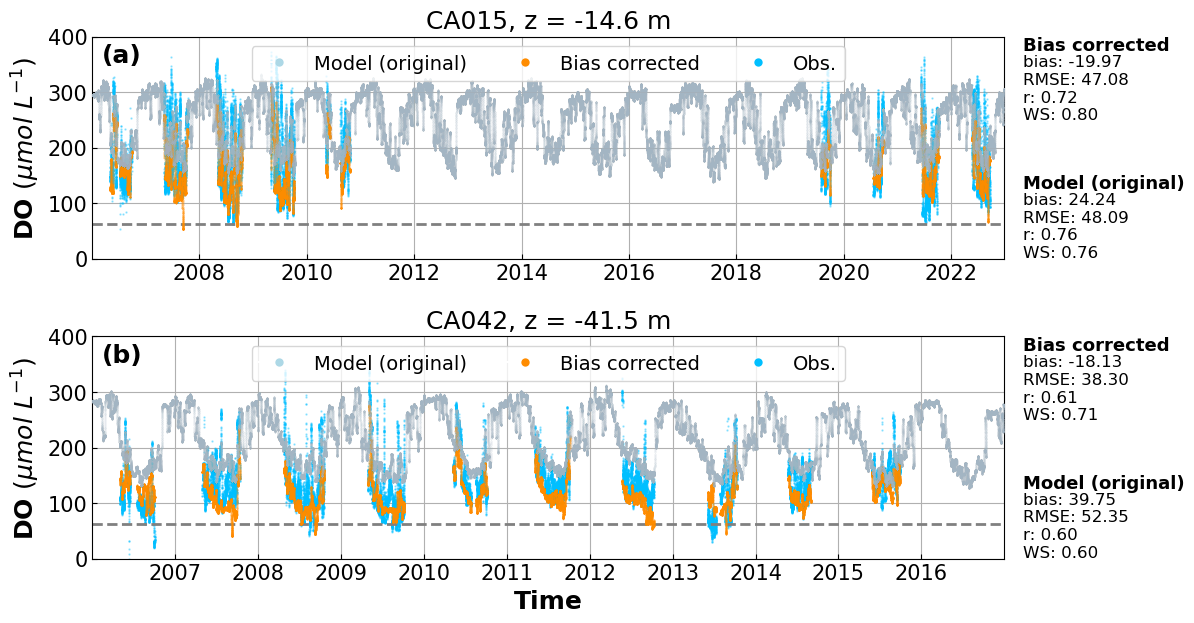

In [107]:
vn = 'DO (uM)'
if len(sn_list) < 3:
    panel_labels = ['(a)', '(b)']

    fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=False)

else:
    panel_labels = ['(a)', '(b)', '(c)']
    fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=False)

for i, (ax, sn, df, obs, yy) in enumerate(zip(axes, sn_list, df_list, obs_list, yy_list)):
    print('mooring:', sn)

    # -----------------------------------
    # apply same logic as the single plot
    # -----------------------------------
    yy_filtered = yy.where(~obs[vn].isna()).clip(lower=0)
    obs_plot = obs[vn].clip(lower=0)
    df_plot = df[vn].clip(lower=0)


    # stats for bias-corrected
    bias_corr, rmse_corr, corr_corr, skill_corr = compute_stats(obs_plot, yy_filtered)
    stats_corr = [bias_corr, rmse_corr, corr_corr, skill_corr]

   # stats for model before
    bias_raw, rmse_raw, corr_raw, skill_raw = compute_stats(obs_plot, df_plot)
    stats_raw  = [bias_raw, rmse_raw, corr_raw, skill_raw]
    # Hypoxia recall: corrected and original model
    recall_corr = hypoxia_recall(obs_plot, yy_filtered)
    recall_raw  = hypoxia_recall(obs_plot, df_plot)

    results_corr = hypoxia_counts(obs_plot, yy_filtered)
    results_raw  = hypoxia_counts(obs_plot, df_plot)

    stats_corr = [bias_corr, rmse_corr, corr_corr, skill_corr, recall_corr, results_corr['F1']]
    stats_raw  = [bias_raw, rmse_raw, corr_raw, skill_raw, recall_raw, results_raw['F1']]

    stats_labels = ['bias', 'RMSE', 'r', 'WS', 'Hypoxia recall', 'F1 score']

    # hypoxia_counts(obs_plot, yy_filtered, threshold=hypoxia_threshold)
    # -----------------------------------
    # scatter plots
    # -----------------------------------
    ax.scatter(df.index.values, df_plot.values,
               s=0.02, color='#A3B5C3', alpha=0.6,  # 'lightblue'
               label="Model (original)", zorder=4)

    ax.scatter(yy_filtered.index.values, yy_filtered.values,
               s=0.1, color='darkorange', alpha=0.6,
               label="Bias corrected", zorder=3)

    ax.scatter(obs.index.values, obs_plot.values,
               s=0.5,
               # color='steelblue',
               color='deepskyblue',
               alpha=0.35,
               label="Obs.", zorder=2)

    # hypoxia threshold
    ax.axhline(y=hypoxia_threshold, color='gray', linewidth=2, linestyle='--')

    # x/y limits
    ax.set_xlim(pd.Timestamp(df.index[0]), pd.Timestamp(df.index[-1]))
    ax.set_ylim([0, 400])

    # bias-corrected stats
    ax.text(1.02, 1.00, 'Bias corrected', fontsize=13, fontweight='bold',
            transform=ax.transAxes, ha='left', va='top')

    for j, (label, val) in enumerate(zip(stats_labels, stats_corr)):
        if sn in ['MB042', 'CA015', 'CA042'] and label in ['Hypoxia recall', 'F1 score']:
            continue

        text = (
            f'{label}: {val:.1%}'
            if label in ['Hypoxia recall', 'F1 score']
            else f'{label}: {val:.2f}'
        )

        ax.text(
            1.02, 0.92 - 0.08 * j, text,
            fontsize=12, transform=ax.transAxes,
            ha='left', va='top'
        )

    # model-before stats
    ax.text(1.02, 0.38, 'Model (original)', fontsize=13, fontweight='bold',
            transform=ax.transAxes, ha='left', va='top')

    for j, (label, val) in enumerate(zip(stats_labels, stats_raw)):
        if label in ['Hypoxia recall', 'F1 score']:
            continue
        text = f'{label}: {val:.2f}'
        # text = f'{label}: {val:.1%}' if label in ['Hypoxia recall','F1 score'] else f'{label}: {val:.2f}'
        ax.text(1.02, 0.30 - 0.08 * j, text, fontsize=12,
                transform=ax.transAxes, ha='left', va='top')
        # panel label
    ax.text(0.01, 0.97, panel_labels[i],
            transform=ax.transAxes,
            fontsize=18, fontweight='bold',
            ha='left', va='top')
    # labels / grid
    ax.set_ylabel('DO $(\\mu mol\\ L^{-1})$')
    ax.grid(True)

    # center-align xtick labels
    for ticklabel in ax.get_xticklabels():
        ticklabel.set_horizontalalignment('center')

    # title

    ax.set_title('%s, z = %0.1f m' % (sn, float(z_list[i])))
    # ax.set_title(f'{sn}')


    # legend on each subplot
    legend_elements = [
        Line2D([0], [0], marker='o', color='w',
               label='Model (original)',
               markerfacecolor='lightblue',

               markeredgecolor='none', markersize=6),

        Line2D([0], [0], marker='o', color='w',
               label='Bias corrected',
               markerfacecolor='darkorange',
               markeredgecolor='none', markersize=6),

        Line2D([0], [0], marker='o', color='w',
               label='Obs.',
               # markerfacecolor='steelblue',
               markerfacecolor='deepskyblue',
               markeredgecolor='none', markersize=6),
    ]

    ax.legend(handles=legend_elements, loc='upper center', ncol=3, fontsize=14)

axes[-1].set_xlabel('Time')

moor_str = "_".join(sn_list)
fig.subplots_adjust(left=0.1, right=0.86, bottom=0.08, top=0.95, hspace=0.35)
plt.savefig(f'{fig_dir}/moor_{moor_str}_3panel_bias_corr_comparison_{runame}_{name}_{f_str}.png',
            dpi=300, bbox_inches='tight')
plt.show()